# 机器视觉入门

本教程依据备课材料中的实验主题与算法改写为 Python，并非原材料 C++ 代码的逐行照抄。

这一本 Notebook 包含环境准备、七项图像处理实践和最后的一次作业。按顺序往下读、往下运行即可。

**如何使用：** 首次从第 1 节安装环境并选择内核；环境准备好后，用单元格左侧的运行按钮逐步执行。想检查完整流程时，选择“重启内核并全部运行”。所有示例图片已在 `assets/` 中提供，结果会自动保存到 `outputs/`。

## 学习顺序

1. 环境准备：Python、VS Code、Jupyter、OpenCV
2. 图像读写与翻转
3. 颜色通道与调整
4. 图像融合
5. 图像直方图
6. 腐蚀与膨胀
7. 图像滤波
8. 边缘提取
9. 一次作业：三张图片、三句说明、一个 PR

各节末尾的问题用于帮助理解，不需要逐题交作业。最终只提交第 9 节的四个文件。


## 1. 环境准备

这一节一次完成 Python 环境、VS Code 扩展和 Notebook 内核的配置，后面不再重复配置。

### 1.1 安装并打开项目

准备 Python **3.11 或 3.12**、VS Code，以及 VS Code 中的 **Python**、**Jupyter** 扩展。克隆培训仓库后，在 VS Code 中打开 `02 机器视觉/lab` 文件夹，再打开本 Notebook。

### 1.2 创建环境并安装依赖

在 VS Code 的终端中执行下面与你的系统对应的命令。终端的当前位置应为 `lab`，能看到 `requirements.txt`。这些是**终端命令**，无需粘贴到 Python 单元格中。首次安装需要联网。

**macOS / Linux：**

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

**Windows PowerShell：**

```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```

上面的 Windows 命令使用 Python 3.12；如果安装的是 3.11，把 `-3.12` 改为 `-3.11`。

### 1.3 选择 Notebook 内核

在右上角点击“选择内核”，选择刚创建的 `.venv` Python 环境。安装依赖时使用的 Python 和 Notebook 内核应属于同一个环境。

现在从下面的 Python 单元格开始运行。如果提示 `No module named cv2`，先检查内核，再确认依赖已安装到该环境。安装包名为 `opencv-python-headless`，代码中的导入名为 `cv2`。

使用独立 JupyterLab 时，在 lab 目录运行 `python -m jupyterlab`；Windows 可运行 `.\.venv\Scripts\python.exe -m jupyterlab`。两种方式使用同一本 Notebook。


**导入工具。** `cv2` 负责图像处理，`np` 负责数组计算，`plt` 负责显示。后续代码都从打开的 lab 文件夹运行。

In [352]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

**约定两个目录。** `Path("assets")` 表示当前 lab 中的素材目录；`Path("outputs")` 表示结果目录。素材已随课程提供，不需要搜索其他位置。

In [353]:
ASSETS = Path("assets")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

**查看版本。** 运行成功说明当前内核能使用 OpenCV。环境安装完成后，后面不再重复配置。

In [354]:
print("OpenCV 版本：", cv2.__version__)

OpenCV 版本： 4.14.0


### 1.4 简单读图工具

后面会反复读图片，所以把这一个动作写成函数。`name` 是文件名，`gray=False` 默认读取彩色图；传入 `gray=True` 时读取灰度图。这里用文件字节解码，兼容 lab 所在的中文目录。

In [355]:
def read_image(name, gray=False):
    image_bytes = np.fromfile(str(ASSETS / name), dtype=np.uint8)
    mode = cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR
    return cv2.imdecode(image_bytes, mode)

**导入对比图排版工具。** `show_images` 只把几张图片并排显示，不进行翻转、滤波等处理。排版代码随 lab 放在 `display_tools.py`，本课不要求学习或打开该文件。后面会先展开演示颜色转换和显示，再复用这个工具。

In [356]:
from display_tools import show_images

### 1.5 验证环境

运行后应看到瓶盖照片，以及图像的高度、宽度和通道数。图中的标题使用英文，说明使用中文，减少电脑字体差异带来的显示问题。

Notebook 中的变量会保留。如果重启内核，需要先重新运行第 1 节，再运行后续章节。每个图像处理章节都会重新读取自己的输入，不依赖上一章的结果。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [357]:
image_path = ASSETS / 'bottle_cap.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
sample_cap = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
if sample_cap is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

运行下面这一步，准备需要的数据并检查结果。

In [358]:
print("图像形状（高、宽、通道）:", sample_cap.shape)
print("数据类型:", sample_cap.dtype)

图像形状（高、宽、通道）: (370, 370, 3)
数据类型: uint8


**显示瓶盖原图。** 运行下面一格，完成创建画布、将 BGR 转为 RGB、绘制和显示。绘图步骤应在同一格中执行，避免提前输出空画布。这里没有修改图片，无需比较变化。


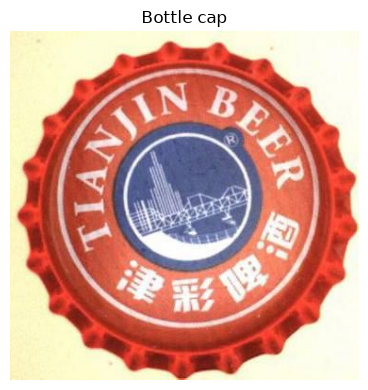

In [359]:
# 创建画布，将 BGR 转为 Matplotlib 显示所需的 RGB 顺序
fig, ax = plt.subplots(figsize=(4, 4))
rgb_picture = cv2.cvtColor(sample_cap, cv2.COLOR_BGR2RGB)

# 显示一次原图
ax.imshow(rgb_picture)
ax.set_title("Bottle cap")
ax.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)


## 2. 图像读写与翻转

**这一节要会：** 读取图片，观察图像数组，完成翻转并保存。

一张彩色图像可以看作“高度 × 宽度 × 3”的数组。`cv2.flip` 的参数为 `1` 时左右翻转，为 `0` 时上下翻转，为 `-1` 时同时翻转两个方向。



### 先认识图像数组

可以把图像想成像素组成的表格。彩色图的每个格子有蓝、绿、红三个数值；灰度图的每个格子只有一个明暗数值。

| 写法 | 含义 |
|---|---|
| `image.shape` | 彩色图通常得到 `(高度, 宽度, 3)` |
| `image.shape[0]` | 高度，即行数 |
| `image.shape[1]` | 宽度，即列数 |
| `image[y, x]` | 第 y 行、第 x 列的像素，编号从 0 开始 |
| `image[y1:y2, x1:x2]` | 取出一块区域；包含起点，不包含终点 |
| `image.copy()` | 复制图像，修改副本时保留原图 |

图片坐标从左上角 `(0, 0)` 开始，x 向右增加，y 向下增加。**数组先写行（y），再写列（x）；OpenCV 的尺寸参数通常先写宽，再写高。** 不必一次记住全部写法，遇到时可以回来看这张表。

### 2.1 读取硬币照片


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [360]:
image_path = ASSETS / 'coins.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
coins = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
if coins is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

运行下面这一步，准备需要的数据并检查结果。

In [361]:
print("shape:", coins.shape, "dtype:", coins.dtype)

shape: (419, 632, 3) dtype: uint8


**显示硬币原图。** 运行下面一格，完成创建画布、将 BGR 转为 RGB、绘制和显示。绘图步骤应在同一格中执行，避免提前输出空画布。这里没有修改图片，无需比较变化。


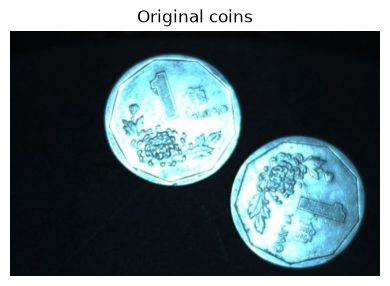

In [362]:
# 创建画布，将 BGR 转为 Matplotlib 显示所需的 RGB 顺序
fig, ax = plt.subplots(figsize=(4, 4))
rgb_picture = cv2.cvtColor(coins, cv2.COLOR_BGR2RGB)

# 显示一次原图
ax.imshow(rgb_picture)
ax.set_title("Original coins")
ax.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)


### 2.2 翻转、保存、重新读取

运行后比较三幅图中硬币的位置。PNG 是无损格式，保存后重新读取应与处理结果逐像素相同。


执行翻转。这里只改变像素的位置，还没有显示或保存结果。

In [363]:
coins_horizontal = cv2.flip(coins, 1)

执行翻转。这里只改变像素的位置，还没有显示或保存结果。

In [364]:
coins_vertical = cv2.flip(coins, 0)

**保存处理后的图像。** 编码为图片文件后写入 outputs，兼容中文路径。

In [365]:
result_path = OUT / 'coins_horizontal.png'
result_path.parent.mkdir(parents=True, exist_ok=True)
ok, encoded = cv2.imencode(result_path.suffix, coins_horizontal)
if not ok:
    raise OSError("图像编码失败。")
encoded.tofile(str(result_path))

运行下面这一步，准备需要的数据并检查结果。

检查两组像素值是否完全相同。这里用于验证保存、重读或翻转后的统计结果；`assert` 条件不成立时会停止并报错。

In [366]:
coins_reloaded = cv2.imdecode(np.fromfile(str(OUT / "coins_horizontal.png"), dtype=np.uint8), cv2.IMREAD_COLOR)
print("保存后像素一致：", np.array_equal(coins_reloaded, coins_horizontal))

保存后像素一致： True


**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

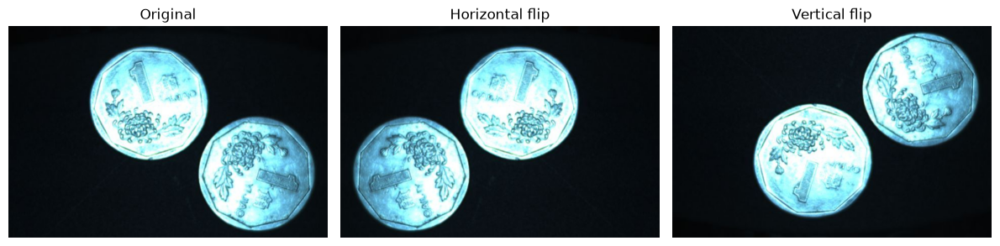

In [367]:
show_images({"Original": coins, "Horizontal flip": coins_horizontal,
             "Vertical flip": coins_vertical}, cols=3,
            save_to="flip_comparison.png")

**停下来观察：** 水平翻转改变的是左右位置，还是上下位置？可把输入改成 `panda.jpg` 再试一次。这是学习练习，无需单独提交。


## 3. 颜色通道与调整

**这一节要会：** 区分 B、G、R 三个通道，修改通道数值，观察颜色变化。

每个通道通常使用 0–255 的整数。把某通道数值调高，会增强它对最终颜色的贡献。计算时先转为浮点数，再裁剪到 0–255，避免 uint8 直接相加发生回绕。

### 3.1 分离三个通道

单通道以灰度显示，越亮表示该通道的数值越大。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [368]:
image_path = ASSETS / 'bottle_cap.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
color_cap = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
if color_cap is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

分离 B、G、R 通道，便于分别观察或处理。

In [369]:
blue_channel, green_channel, red_channel = cv2.split(color_cap)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

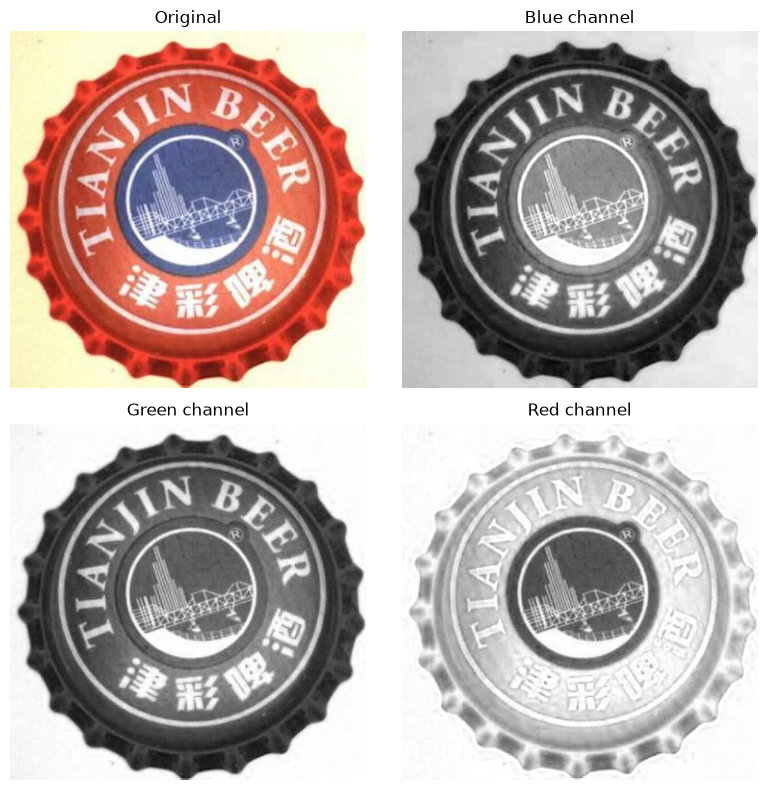

In [370]:
show_images({"Original": color_cap, "Blue channel": blue_channel,
             "Green channel": green_channel, "Red channel": red_channel}, cols=2,
            save_to="color_channels.png")

### 3.2 修改通道

下面的 `(0, 0, 40)` 表示蓝色不变、绿色不变、红色增加 40。可以将最后的 40 改成 80，再运行这一格，比较瓶盖颜色的变化。


**这一格的作用：** 得到 `offset_bgr`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [371]:
offset_bgr = np.array([0, 0, 40], dtype=np.float32)

计算新的像素值，并限制在 0–255 范围内，再转换为 uint8。

`np.clip(数值, 0, 255)` 把小于 0 的值设为 0、大于 255 的值设为 255。先转浮点数再计算，最后转回 uint8，防止整数回绕。

In [372]:
color_adjusted = np.clip(color_cap.astype(np.float32) + offset_bgr, 0, 255).astype(np.uint8)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

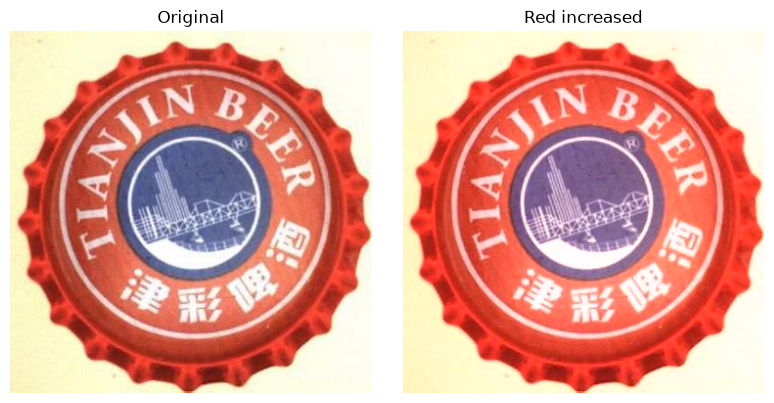

In [373]:
show_images({"Original": color_cap, "Red increased": color_adjusted}, cols=2,
            save_to="color_comparison.png")

**保存处理后的图像。** 编码为图片文件后写入 outputs，兼容中文路径。

In [374]:
result_path = OUT / 'cap_color_adjusted.png'
result_path.parent.mkdir(parents=True, exist_ok=True)
ok, encoded = cv2.imencode(result_path.suffix, color_adjusted)
if not ok:
    raise OSError("图像编码失败。")
encoded.tofile(str(result_path))

### 3.3 颜色量化

量化将接近的像素值归到同一个等级，例如每 64 个数值归为一组。等级越少，色块越明显。下面的中间计算使用 uint16，最后再转回 uint8。


运行下面这一步，准备需要的数据并检查结果。

量化先用 uint16 保存中间数值，避免计算超出 uint8 范围；`//` 是整除。例如步长 64 时，0–63 会归到同一组。

In [375]:
quantization_step = 64
color_work = color_cap.astype(np.uint16)

计算新的像素值，并限制在 0–255 范围内，再转换为 uint8。

`np.clip(数值, 0, 255)` 把小于 0 的值设为 0、大于 255 的值设为 255。先转浮点数再计算，最后转回 uint8，防止整数回绕。

In [376]:
color_quantized = np.clip((color_work // quantization_step) * quantization_step
                          + quantization_step // 2, 0, 255).astype(np.uint8)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

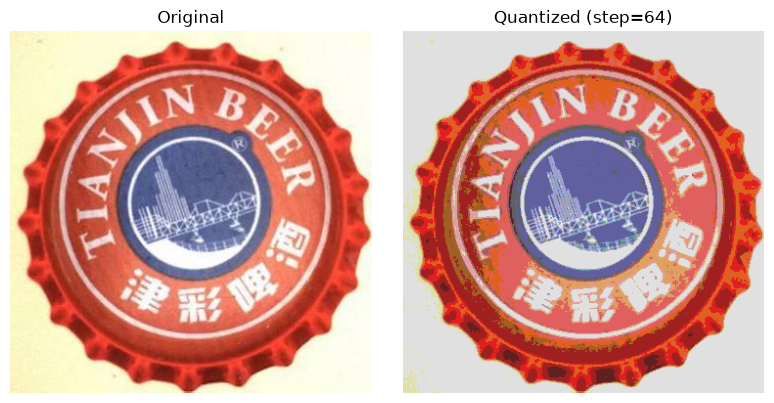

In [377]:
show_images({"Original": color_cap, "Quantized (step=64)": color_quantized}, cols=2,
            save_to="quantization.png")

**停下来观察：** 增加红色通道与减少颜色等级，产生的变化一样吗？也可以把偏移量改为 `(40, 0, 0)`，观察蓝色通道增加后的效果。


## 4. 图像融合

**必学目标：** 把两张相同尺寸的图片按比例混合，改变比例并观察效果。先做整张图片融合；局部区域操作放在后面的选学部分。

### 4.1 读取两张图片

熊猫作为第一张，瓶盖作为第二张。这里复用已经讲过的读图工具；它只负责从 assets 读取图片。

In [378]:
blend_background = read_image("panda.jpg")
blend_cap = read_image("bottle_cap.png")
print("熊猫尺寸：", blend_background.shape)
print("瓶盖尺寸：", blend_cap.shape)

熊猫尺寸： (891, 891, 3)
瓶盖尺寸： (370, 370, 3)


### 4.2 先把尺寸统一

直接逐像素相加时，两张图片需要一样宽、一样高。这里统一到 370×370；为了简单，允许把熊猫缩成正方形，可能改变其比例。`resize` 的参数是 `(宽, 高)`；`INTER_AREA` 适合缩小图片。

In [379]:
blend_size = (370, 370)
blend_image1 = cv2.resize(blend_background, blend_size, interpolation=cv2.INTER_AREA)
blend_image2 = cv2.resize(blend_cap, blend_size, interpolation=cv2.INTER_AREA)

先检查输入。两张图的外框应大小一致；这一格没有进行融合。

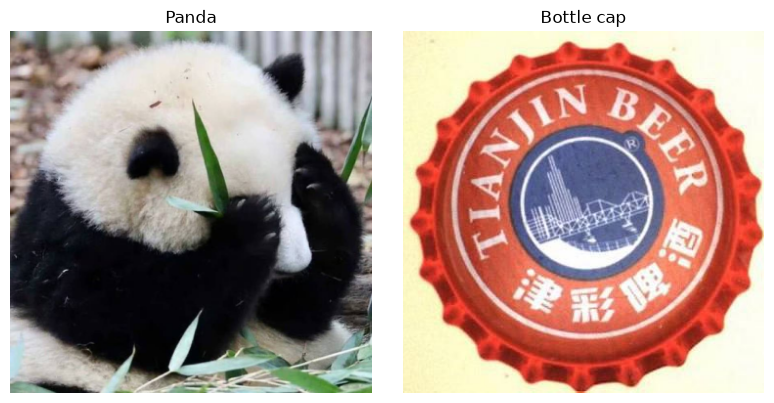

In [380]:
show_images({"Panda": blend_image1, "Bottle cap": blend_image2}, cols=2)

### 4.3 按比例融合

`alpha` 是瓶盖所占的比例，熊猫比例为 `1-alpha`。下面各占一半。`addWeighted` 最后一个 `0` 表示不额外增加亮度。每个输出像素由两张输入图相同位置的像素加权得到。

In [381]:
alpha = 0.5
blend_result = cv2.addWeighted(blend_image1, 1-alpha, blend_image2, alpha, 0)

显示融合结果。尝试将 alpha 改为 0.2 或 0.8，重新运行上一格和这一格，观察哪张图更明显。

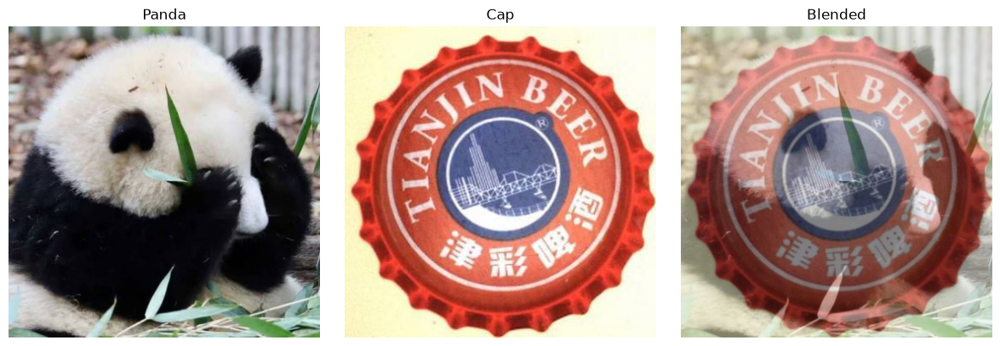

In [382]:
show_images({"Panda": blend_image1, "Cap": blend_image2, "Blended": blend_result},
            cols=3, save_to="blend_comparison.png")

### 4.4 选学：只在左下角融合

这部分不是作业要求。ROI 是 Region of Interest，即“感兴趣区域”，就是从大图里选出的一块。先确定区域位置，画框确认，再取出区域进行融合。

图片左上角是原点，x 向右、y 向下。下面选一块宽高均为 180 像素的方形，距左边 20 像素、距底边 20 像素。

In [383]:
roi_width = 180
roi_height = 180
roi_x = 20
roi_y = blend_background.shape[0] - roi_height - 20

检查框没有超出图片。右边界是 `x+宽度`，下边界是 `y+高度`。条件不成立时 assert 报错；可先缩小区域或调整位置。

In [384]:
assert roi_x >= 0 and roi_y >= 0
assert roi_x + roi_width <= blend_background.shape[1]
assert roi_y + roi_height <= blend_background.shape[0]

**先画框。** 在原图副本上画绿色矩形，保留原图不变。矩形两个角按 `(x, y)` 写；颜色 `(0, 255, 0)` 是 BGR 的绿色，`2` 是线宽。看清楚这个框在哪里，再继续。

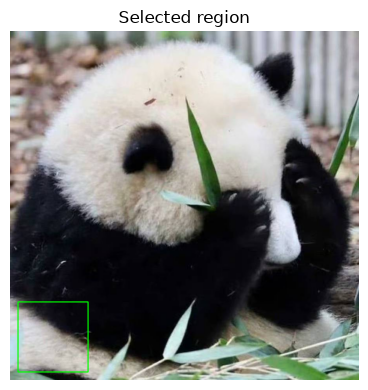

In [385]:
roi_preview = blend_background.copy()
cv2.rectangle(roi_preview, (roi_x, roi_y),
              (roi_x + roi_width - 1, roi_y + roi_height - 1), (0, 255, 0), 2)
show_images({"Selected region": roi_preview}, cols=1, save_to="roi_location.png")

**再取出区域。** 数组切片先写 y 范围，再写 x 范围，结束位置不包含在内。得到的 roi 是熊猫照片中的 180×180 小图；瓶盖也缩成相同大小。

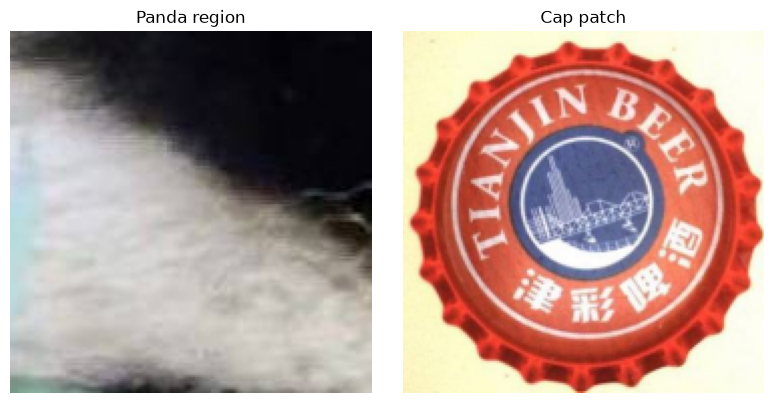

In [386]:
roi = blend_background[roi_y:roi_y+roi_height, roi_x:roi_x+roi_width]
roi_patch = cv2.resize(blend_cap, (roi_width, roi_height), interpolation=cv2.INTER_AREA)
show_images({"Panda region": roi, "Cap patch": roi_patch}, cols=2)

对这两张小图按各一半融合，再放回熊猫照片副本的相同位置。先完成计算，最后显示整张照片，观察只有选中的区域改变。

In [387]:
roi_blended = cv2.addWeighted(roi, 0.5, roi_patch, 0.5, 0)
roi_result = blend_background.copy()
roi_result[roi_y:roi_y+roi_height, roi_x:roi_x+roi_width] = roi_blended

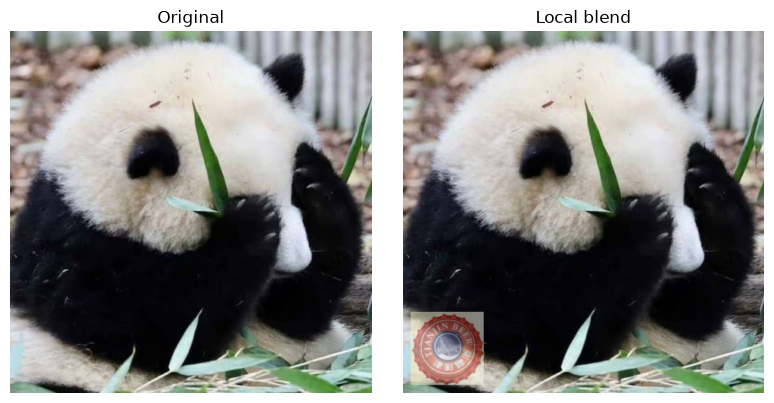

In [388]:
show_images({"Original": blend_background, "Local blend": roi_result},
            cols=2, save_to="roi_blend.png")

**停下来观察：** 整图融合与局部融合，改变的区域有什么区别？只学习主线时，理解 alpha 的作用即可。

## 5. 图像直方图

**这一节要会：** 看懂横轴的灰度值和纵轴的像素数量。

灰度直方图统计 0–255 各个灰度级有多少像素。它描述明暗分布，不记录像素在图中什么位置。OpenCV 的范围写成 `[0, 256]`，右端 256 不包含在统计区间中。

### 5.1 瓶盖灰度直方图

观察瓶盖的浅色背景，并找出它在直方图中大致对应的区间。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [389]:
image_path = ASSETS / 'bottle_cap.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
hist_cap = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
if hist_cap is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

转换颜色表示。注意这里转换的是显示用 RGB，还是计算用灰度。

In [390]:
hist_gray = cv2.cvtColor(hist_cap, cv2.COLOR_BGR2GRAY)

运行下面这一步，准备需要的数据并检查结果。

`calcHist` 的 `[0]` 表示统计第 0 个通道，`[256]` 表示分成 256 个格子，`[0, 256]` 是统计范围。`ravel()` 把结果整理为一列数，便于画图。

In [391]:
hist_counts = cv2.calcHist([hist_gray], [0], None, [256], [0, 256]).ravel()
print("直方图像素总数：", int(hist_counts.sum()))

直方图像素总数： 136900


**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

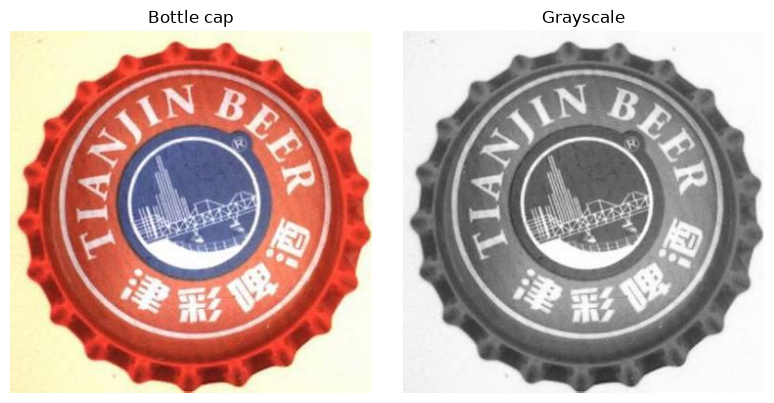

In [392]:
show_images({"Bottle cap": hist_cap, "Grayscale": hist_gray}, cols=2)

**这一格的作用：** 得到 `hist_fig, hist_ax`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

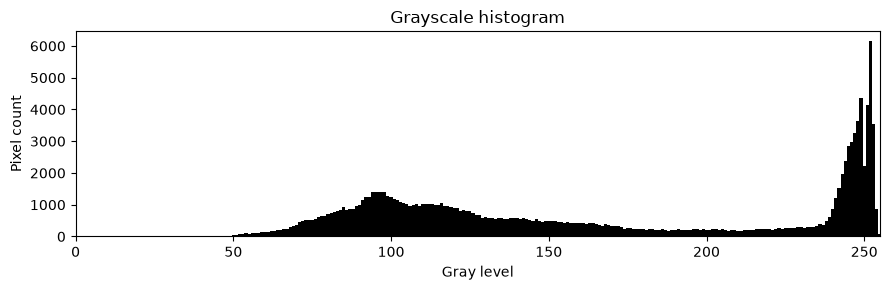

In [393]:
hist_fig, hist_ax = plt.subplots(figsize=(9, 3))
hist_ax.bar(np.arange(256), hist_counts, width=1, color="black")
hist_ax.set(xlim=(0, 255), xlabel="Gray level", ylabel="Pixel count", title="Grayscale histogram")
hist_fig.tight_layout()
hist_fig.savefig(OUT / "gray_histogram.png", dpi=120)
plt.show()

运行下面这一步，准备需要的数据并检查结果。

In [394]:
plt.close(hist_fig)

### 5.2 分别统计三个颜色通道

三条曲线分别表示蓝、绿、红通道的数值分布。


**绘制颜色通道直方图。** 在同一格中创建画布，分别统计蓝、绿、红通道，再添加图例、保存并显示。比较三条曲线在不同像素值处的分布。


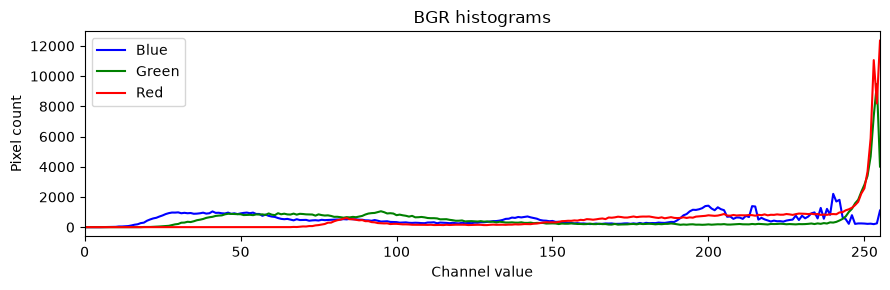

In [395]:
hist_color_fig, hist_color_ax = plt.subplots(figsize=(9, 3))

for hist_channel, hist_color, hist_label in [(0, "b", "Blue"), (1, "g", "Green"), (2, "r", "Red")]:
    hist_values = cv2.calcHist([hist_cap], [hist_channel], None, [256], [0, 256]).ravel()
    hist_color_ax.plot(hist_values, color=hist_color, label=hist_label)

hist_color_ax.set(xlim=(0, 255), xlabel="Channel value", ylabel="Pixel count", title="BGR histograms")
hist_color_ax.legend()
hist_color_fig.tight_layout()
hist_color_fig.savefig(OUT / "color_histograms.png", dpi=120)
plt.show()
plt.close(hist_color_fig)

**停下来观察：** 瓶盖背景较亮，直方图哪一端的像素较多？把图像水平翻转，直方图会改变吗？下面验证第二个问题。


执行翻转。这里只改变像素的位置，还没有显示或保存结果。

`calcHist` 的 `[0]` 表示统计第 0 个通道，`[256]` 表示分成 256 个格子，`[0, 256]` 是统计范围。`ravel()` 把结果整理为一列数，便于画图。

In [396]:
hist_flipped = cv2.calcHist([cv2.flip(hist_gray, 1)], [0], None, [256], [0, 256]).ravel()

运行下面这一步，准备需要的数据并检查结果。

检查两组像素值是否完全相同。这里用于验证保存、重读或翻转后的统计结果；`assert` 条件不成立时会停止并报错。

In [397]:
print("翻转前后直方图相同：", np.array_equal(hist_counts, hist_flipped))
print("翻转前后像素位置改变，但灰度直方图相同。")

翻转前后直方图相同： True
翻转前后像素位置改变，但灰度直方图相同。


## 6. 腐蚀与膨胀

**这一节要会：** 区分灰度图与白色前景二值图中的变化。

灰度腐蚀在局部区域取最小值，膨胀取最大值。当二值图以白色为前景时，腐蚀使白色区域缩小，膨胀使白色区域扩大。结构元素（核）定义了处理时观察的邻域。

### 6.1 对电路板灰度图处理

电路板芯片较暗。灰度腐蚀会使暗色区域扩大，因此不能把“腐蚀”直接理解为任何物体都变小。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [398]:
image_path = ASSETS / 'circuit_board.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
morph_board = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if morph_board is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

运行下面这一步，准备需要的数据并检查结果。

结构元素就是处理像素时使用的小模板。`(3, 3)` 表示宽 3、高 3；矩形核观察一个方形邻域，椭圆核的形状更接近圆。

In [399]:
morph_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

进行腐蚀处理，下一步再与原图比较。

In [400]:
morph_eroded = cv2.erode(morph_board, morph_kernel, iterations=1)

进行膨胀处理，观察明亮区域的变化。

In [401]:
morph_dilated = cv2.dilate(morph_board, morph_kernel, iterations=1)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

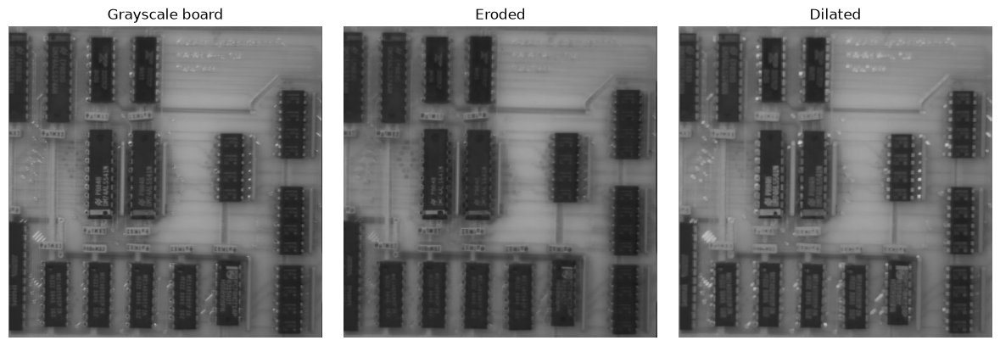

In [402]:
show_images({"Grayscale board": morph_board, "Eroded": morph_eroded,
             "Dilated": morph_dilated}, cols=3, save_to="board_morphology.png")

### 6.2 把零件设为白色前景

原照片中的零件较暗。使用反二值化，并让 Otsu 方法自动选择阈值，得到“白色零件、黑色背景”的二值图，再比较处理后的边界和孔洞。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [403]:
image_path = ASSETS / 'mechanical_part.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
morph_part = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if morph_part is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

执行阈值处理，得到二值图；观察白色区域代表什么。

`threshold` 返回两个结果：阈值和二值图。`THRESH_BINARY_INV` 把较暗区域变成白色；`THRESH_OTSU` 自动选择分界值。零件较暗，所以这里采用反二值化。

In [404]:
morph_threshold, morph_binary = cv2.threshold(morph_part, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)

运行下面这一步，准备需要的数据并检查结果。

结构元素就是处理像素时使用的小模板。`(3, 3)` 表示宽 3、高 3；矩形核观察一个方形邻域，椭圆核的形状更接近圆。

In [405]:
morph_part_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

进行腐蚀处理，下一步再与原图比较。

In [406]:
morph_part_eroded = cv2.erode(morph_binary, morph_part_kernel)

进行膨胀处理，观察明亮区域的变化。

In [407]:
morph_part_dilated = cv2.dilate(morph_binary, morph_part_kernel)

对几组参数重复相同的处理，收集用于对比的结果。先读懂循环内的一次操作，再观察整体变化。

二值图中黑色是 0，白色是 255。统计非零像素个数，就得到白色区域的面积，单位是像素。

In [408]:
morph_areas = [int(np.count_nonzero(a)) for a in (morph_part_eroded, morph_binary, morph_part_dilated)]

运行下面这一步，准备需要的数据并检查结果。

In [409]:
print("白色面积 [腐蚀后, 原始, 膨胀后]:", morph_areas)

白色面积 [腐蚀后, 原始, 膨胀后]: [88813, 100715, 111569]


**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

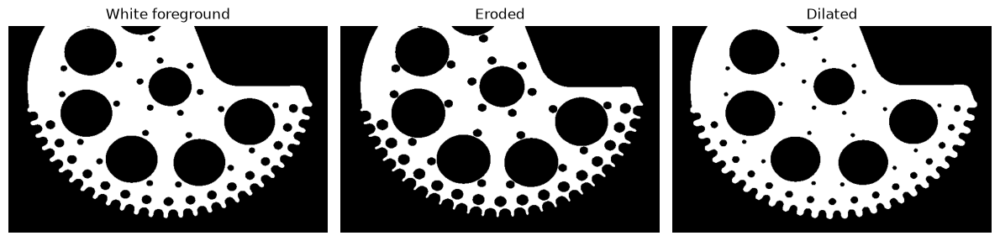

In [410]:
show_images({"White foreground": morph_binary, "Eroded": morph_part_eroded,
             "Dilated": morph_part_dilated}, cols=3, save_to="binary_morphology.png")

### 6.3 延伸观察：开运算与闭运算

开运算先腐蚀再膨胀，闭运算先膨胀再腐蚀。尝试观察它们对细小突出和细小孔洞的影响。这部分不需要交作业。


**这一格的作用：** 得到 `morph_opened`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [411]:
morph_opened = cv2.morphologyEx(morph_binary, cv2.MORPH_OPEN, morph_part_kernel)
morph_closed = cv2.morphologyEx(morph_binary, cv2.MORPH_CLOSE, morph_part_kernel)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

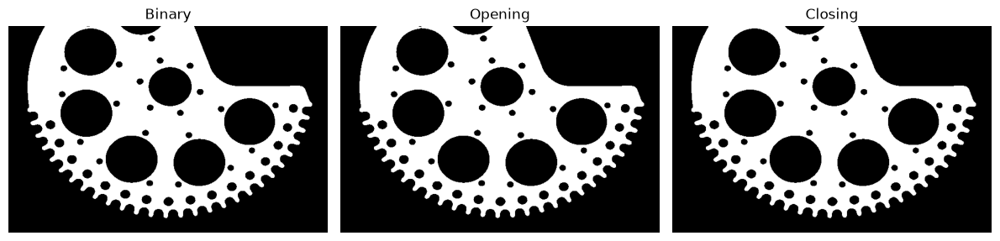

In [412]:
show_images({"Binary": morph_binary, "Opening": morph_opened,
             "Closing": morph_closed}, cols=3, save_to="opening_closing.png")

**停下来观察：** 白色零件腐蚀后，外轮廓和内部黑色孔洞分别怎样变化？把核从 5×5 改成 9×9，细节会怎样？


## 7. 图像滤波

**这一节要会：** 选择一种滤波方法，观察噪点是否减少、细节是否变模糊。

滤波使用像素附近的值来计算新的像素值。均值滤波使用邻域平均值；高斯滤波对距离中心更近的像素赋予更大权重；中值滤波取邻域中间的数值，常用于椒盐噪声。

### 7.1 准备带噪声的瓶盖图

用原图生成高斯噪声图和椒盐噪声图。随机种子固定为 2026，便于重复观察。原始素材不被覆盖。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [413]:
image_path = ASSETS / 'bottle_cap.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
filter_clean = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if filter_clean is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

运行下面这一步，准备需要的数据并检查结果。

随机数用于模拟噪声。固定种子 2026 后，重新运行能得到同样的噪声，方便比较。它不是图像处理算法的参数。

In [414]:
filter_rng = np.random.default_rng(2026)

计算新的像素值，并限制在 0–255 范围内，再转换为 uint8。

`np.clip(数值, 0, 255)` 把小于 0 的值设为 0、大于 255 的值设为 255。先转浮点数再计算，最后转回 uint8，防止整数回绕。

In [415]:
filter_gaussian_input = np.clip(filter_clean.astype(np.float32)
    + filter_rng.normal(0, 20, filter_clean.shape), 0, 255).astype(np.uint8)

**这一格的作用：** 得到 `filter_salt_input`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [416]:
filter_salt_input = filter_clean.copy()
filter_random = filter_rng.random(filter_clean.shape)
filter_salt_input[filter_random < 0.025] = 0
filter_salt_input[filter_random > 0.975] = 255

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

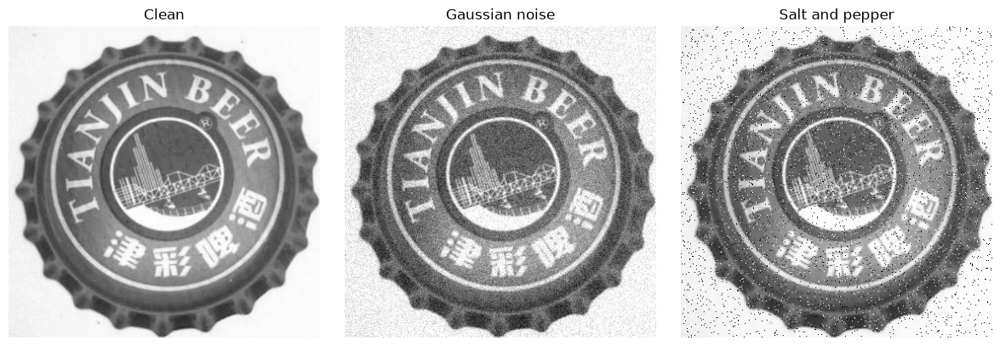

In [417]:
show_images({"Clean": filter_clean, "Gaussian noise": filter_gaussian_input,
             "Salt and pepper": filter_salt_input}, cols=3, save_to="noise_inputs.png")

**保存处理后的图像。** 编码为图片文件后写入 outputs，兼容中文路径。

In [418]:
result_path = OUT / 'cap_gaussian_noise.png'
result_path.parent.mkdir(parents=True, exist_ok=True)
ok, encoded = cv2.imencode(result_path.suffix, filter_gaussian_input)
if not ok:
    raise OSError("图像编码失败。")
encoded.tofile(str(result_path))

**保存处理后的图像。** 编码为图片文件后写入 outputs，兼容中文路径。

In [419]:
result_path = OUT / 'cap_salt_pepper.png'
result_path.parent.mkdir(parents=True, exist_ok=True)
ok, encoded = cv2.imencode(result_path.suffix, filter_salt_input)
if not ok:
    raise OSError("图像编码失败。")
encoded.tofile(str(result_path))

### 7.2 比较三种滤波

先在椒盐噪声图上比较。核大小都取 5，观察黑白噪点、文字和瓶盖边缘。不需要计算误差。


执行滤波。先得到处理结果，再观察噪点与细节。

In [420]:
filter_mean = cv2.blur(filter_salt_input, (5, 5))

执行滤波。先得到处理结果，再观察噪点与细节。

`(5, 5)` 表示邻域宽高；后面的数值控制高斯权重分布。滤波之后观察噪点是否减少，同时检查文字和边界是否变模糊。

In [421]:
filter_gaussian = cv2.GaussianBlur(filter_salt_input, (5, 5), 1.2)

执行滤波。先得到处理结果，再观察噪点与细节。

参数 `5` 表示对每个像素周围 5×5 区域取中间值。这一格只计算结果，下一步才显示；可以先预测黑白噪点会怎样变化。

In [422]:
filter_median = cv2.medianBlur(filter_salt_input, 5)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

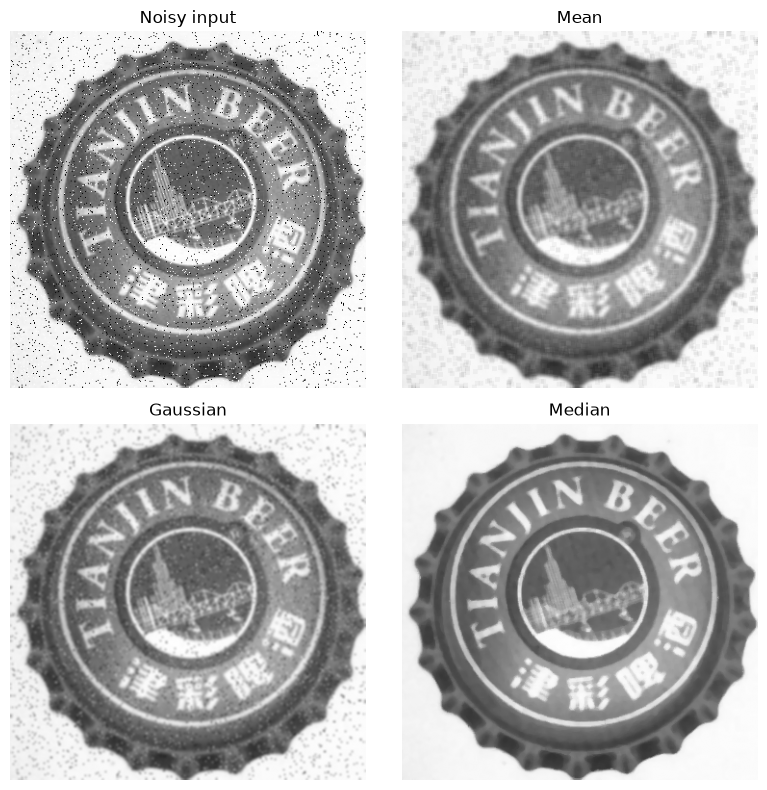

In [423]:
show_images({"Noisy input": filter_salt_input, "Mean": filter_mean,
             "Gaussian": filter_gaussian, "Median": filter_median}, cols=2,
            save_to="filter_comparison.png")

### 7.3 延伸观察：平滑与锐化

在电路板上比较高斯、中值滤波。然后用“原图减去平滑图”得到高频细节，再把一部分细节加回原图，观察锐化。浮点运算可以保留差值中的负数。这部分不需要交作业。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [424]:
image_path = ASSETS / 'circuit_board.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
filter_board = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if filter_board is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

`(5, 5)` 表示邻域宽高；后面的数值控制高斯权重分布。滤波之后观察噪点是否减少，同时检查文字和边界是否变模糊。

参数 `5` 表示对每个像素周围 5×5 区域取中间值。这一格只计算结果，下一步才显示；可以先预测黑白噪点会怎样变化。

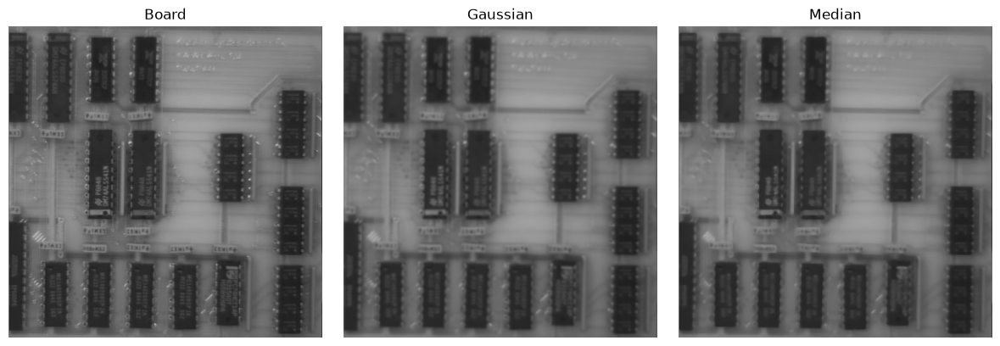

In [425]:
show_images({"Board": filter_board, "Gaussian": cv2.GaussianBlur(filter_board, (5, 5), 1.5),
             "Median": cv2.medianBlur(filter_board, 5)}, cols=3, save_to="board_filters.png")

执行滤波。先得到处理结果，再观察噪点与细节。

`(5, 5)` 表示邻域宽高；后面的数值控制高斯权重分布。滤波之后观察噪点是否减少，同时检查文字和边界是否变模糊。

In [426]:
filter_lowpass = cv2.GaussianBlur(filter_clean, (5, 5), 1.2).astype(np.float32)

**这一格的作用：** 得到 `filter_detail`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [427]:
filter_detail = filter_clean.astype(np.float32) - filter_lowpass

计算新的像素值，并限制在 0–255 范围内，再转换为 uint8。

`np.clip(数值, 0, 255)` 把小于 0 的值设为 0、大于 255 的值设为 255。先转浮点数再计算，最后转回 uint8，防止整数回绕。

In [428]:
filter_sharpened = np.clip(filter_clean.astype(np.float32) + filter_detail, 0, 255).astype(np.uint8)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

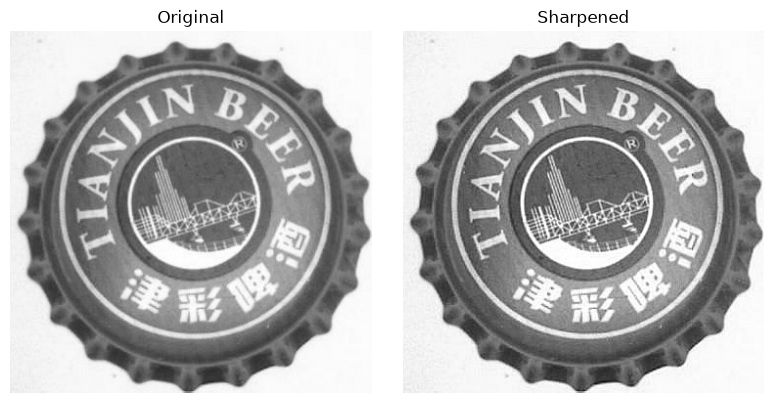

In [429]:
show_images({"Original": filter_clean, "Sharpened": filter_sharpened}, cols=2,
            save_to="sharpening.png")

**停下来观察：** 你认为哪幅图中的噪点最少？文字是否也变模糊了？可以把同一组滤波代码中的输入换成 `filter_gaussian_input`，观察另一种噪声。


## 8. 边缘提取

**这一节要会：** 观察两个方向的亮度变化，合成边缘，再调整阈值。

Sobel x 计算沿 x 方向的亮度变化，通常对竖直边缘响应强；Sobel y 通常对水平边缘响应强。梯度有正负值，先使用 float32 计算，取绝对值并合成后再转换为显示图，避免直接用 uint8 丢失负梯度。

### 8.1 计算方向梯度与合成结果


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [430]:
image_path = ASSETS / 'mechanical_part.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
edge_part = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if edge_part is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

执行滤波。先得到处理结果，再观察噪点与细节。

`(5, 5)` 表示邻域宽高；后面的数值控制高斯权重分布。滤波之后观察噪点是否减少，同时检查文字和边界是否变模糊。

In [431]:
edge_smoothed = cv2.GaussianBlur(edge_part, (3, 3), 0)

计算方向梯度。使用浮点数保留正负变化，暂不转换为显示图。

`CV_32F` 让结果保留浮点数和负数；`1, 0` 表示计算 x 方向变化，`0, 1` 表示 y 方向变化。`ksize=3` 表示使用 3×3 的邻域。

In [432]:
edge_x = cv2.Sobel(edge_smoothed, cv2.CV_32F, 1, 0, ksize=3)

计算方向梯度。使用浮点数保留正负变化，暂不转换为显示图。

`CV_32F` 让结果保留浮点数和负数；`1, 0` 表示计算 x 方向变化，`0, 1` 表示 y 方向变化。`ksize=3` 表示使用 3×3 的邻域。

In [433]:
edge_y = cv2.Sobel(edge_smoothed, cv2.CV_32F, 0, 1, ksize=3)

计算新的像素值，并限制在 0–255 范围内，再转换为 uint8。

`np.clip(数值, 0, 255)` 把小于 0 的值设为 0、大于 255 的值设为 255。先转浮点数再计算，最后转回 uint8，防止整数回绕。

In [434]:
def normalize_edges(values):
    maximum = float(values.max())
    if maximum == 0:
        return np.zeros(values.shape, dtype=np.uint8)
    return np.clip(values * (255.0 / maximum), 0, 255).astype(np.uint8)

**这一格的作用：** 得到 `edge_strength`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [435]:
edge_strength = normalize_edges(np.abs(edge_x) + np.abs(edge_y))
assert normalize_edges(np.zeros((8, 8), dtype=np.float32)).max() == 0

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

取梯度绝对值并转换到 0–255，便于显示。方向梯度的原始浮点数组仍保留，用它来合成边缘，避免显示转换影响计算。

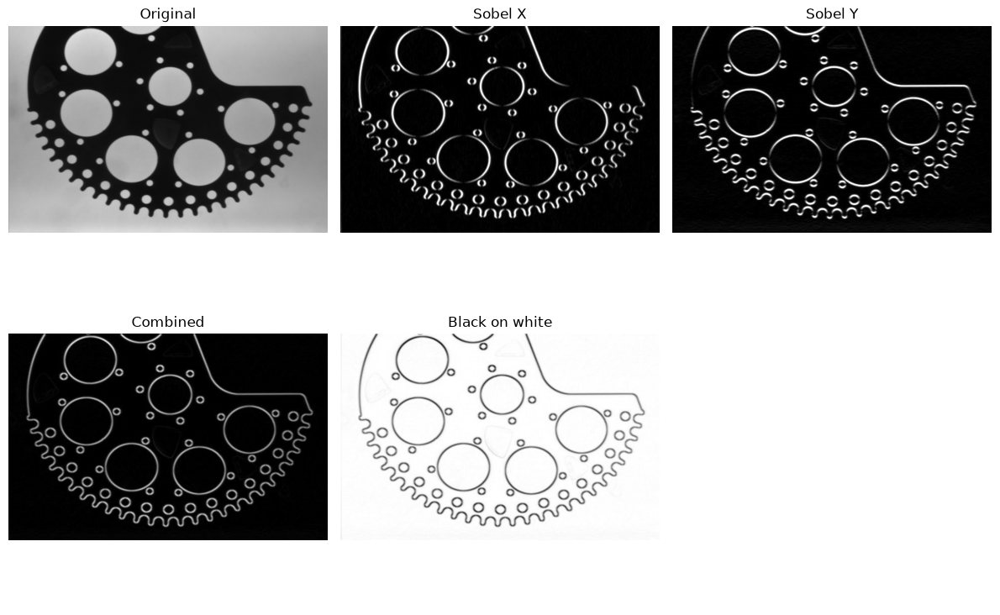

In [436]:
show_images({"Original": edge_part, "Sobel X": cv2.convertScaleAbs(edge_x),
             "Sobel Y": cv2.convertScaleAbs(edge_y), "Combined": edge_strength,
             "Black on white": 255-edge_strength}, cols=3, save_to="sobel_comparison.png")

### 8.2 观察阈值的影响

在归一化的边缘强度上设阈值，超过阈值的像素保留为白色。阈值越高，保留的边缘像素通常越少。


**这一格的作用：** 得到 `edge_views`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [437]:
edge_views = {"Magnitude": edge_strength}
edge_counts = []

执行阈值处理，得到二值图；观察白色区域代表什么。

`threshold` 返回两个结果：阈值和二值图。`THRESH_BINARY_INV` 把较暗区域变成白色；`THRESH_OTSU` 自动选择分界值。零件较暗，所以这里采用反二值化。

二值图中黑色是 0，白色是 255。统计非零像素个数，就得到白色区域的面积，单位是像素。

In [438]:
for edge_threshold in (30, 70, 120):
    _, edge_binary = cv2.threshold(edge_strength, edge_threshold, 255, cv2.THRESH_BINARY)
    edge_views[f"Threshold={edge_threshold}"] = edge_binary
    edge_counts.append(int(np.count_nonzero(edge_binary)))

运行下面这一步，准备需要的数据并检查结果。

In [439]:
assert edge_counts[0] >= edge_counts[1] >= edge_counts[2]

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

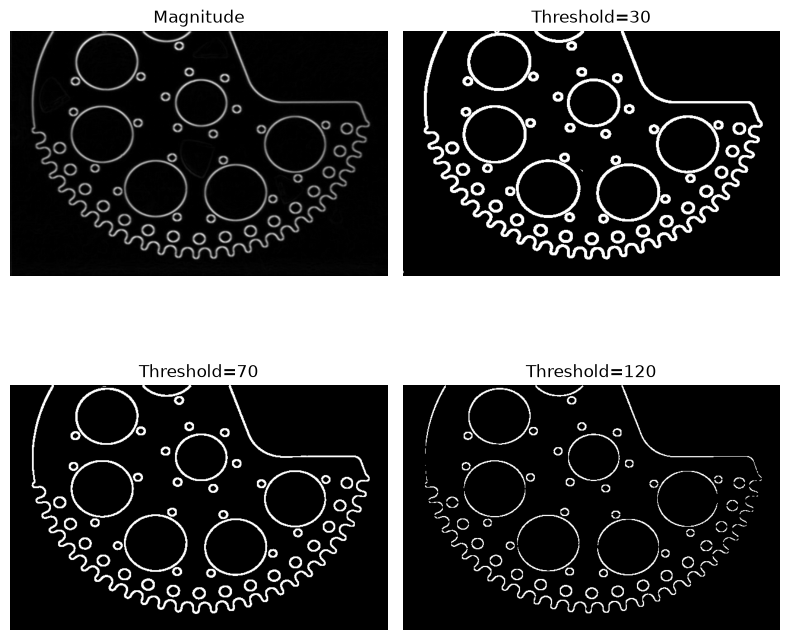

In [440]:
show_images(edge_views, cols=2, save_to="edge_thresholds.png")

### 8.3 换成自然照片

熊猫毛发和竹叶有很多纹理。与机械零件相比，边缘提取可能得到更多内部细节。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [441]:
image_path = ASSETS / 'panda.jpg'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
edge_panda = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if edge_panda is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

执行滤波。先得到处理结果，再观察噪点与细节。

`(5, 5)` 表示邻域宽高；后面的数值控制高斯权重分布。滤波之后观察噪点是否减少，同时检查文字和边界是否变模糊。

In [442]:
edge_panda_blur = cv2.GaussianBlur(edge_panda, (5, 5), 1.2)

计算方向梯度。使用浮点数保留正负变化，暂不转换为显示图。

`CV_32F` 让结果保留浮点数和负数；`1, 0` 表示计算 x 方向变化，`0, 1` 表示 y 方向变化。`ksize=3` 表示使用 3×3 的邻域。

In [443]:
edge_panda_x = cv2.Sobel(edge_panda_blur, cv2.CV_32F, 1, 0, ksize=3)

计算方向梯度。使用浮点数保留正负变化，暂不转换为显示图。

`CV_32F` 让结果保留浮点数和负数；`1, 0` 表示计算 x 方向变化，`0, 1` 表示 y 方向变化。`ksize=3` 表示使用 3×3 的邻域。

In [444]:
edge_panda_y = cv2.Sobel(edge_panda_blur, cv2.CV_32F, 0, 1, ksize=3)

**这一格的作用：** 得到 `edge_panda_result`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [445]:
edge_panda_result = normalize_edges(cv2.magnitude(edge_panda_x, edge_panda_y))

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

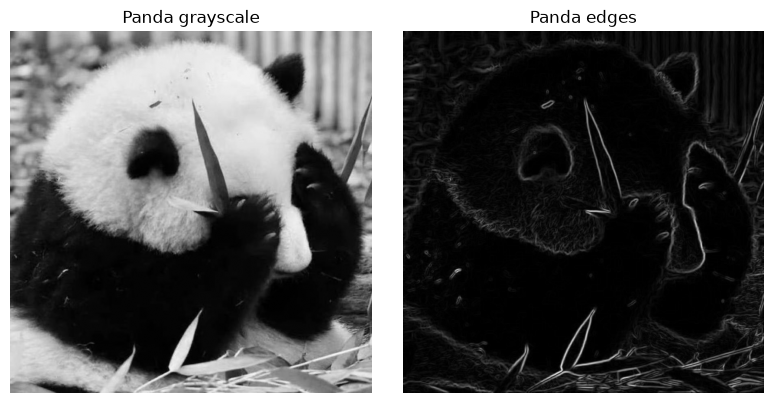

In [446]:
show_images({"Panda grayscale": edge_panda, "Panda edges": edge_panda_result}, cols=2,
            save_to="panda_edges.png")

**停下来观察：** 边缘图是否只保留物体的外轮廓？提高阈值后，哪些线条先消失？


## 9. 一次作业：三张图片、三句说明、一个 PR

作业只交一次。下面三个任务的代码会生成需要提交的三张对比图。只需运行第 1 节准备环境，再依次运行本节代码块，也能生成作业图片；它们不依赖前面练习中保存的变量。

**任务一：水平翻转。** 运行下面的代码块，观察原图与水平翻转结果中硬币位置的变化。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [447]:
image_path = ASSETS / 'coins.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
hw_coins = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
if hw_coins is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

执行翻转。这里只改变像素的位置，还没有显示或保存结果。

In [448]:
hw_coins_flipped = cv2.flip(hw_coins, 1)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

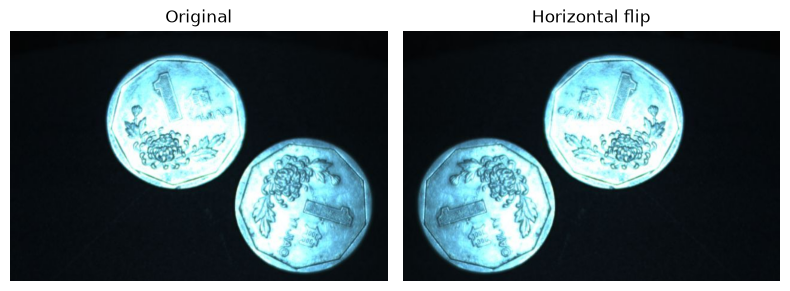

In [449]:
show_images({"Original": hw_coins, "Horizontal flip": hw_coins_flipped}, cols=2,
            save_to="作业图片/01_flip.png")

运行下面这一步，准备需要的数据并检查结果。

In [450]:
print("已保存：outputs/作业图片/01_flip.png")

已保存：outputs/作业图片/01_flip.png


**任务二：颜色调整。** 课堂示例给红色通道增加 40。这里将它改成 80，再运行；也可以选择其他偏移量。观察调整前后的变化，并记下自己修改的通道和数值。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [451]:
image_path = ASSETS / 'bottle_cap.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
hw_cap = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)
if hw_cap is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

**这一格的作用：** 得到 `hw_offset_bgr`，供后面的计算或显示使用。`=` 表示把右边的结果存入左边的变量。

先运行这一格，再阅读紧接着的显示或处理步骤。

In [452]:
hw_offset_bgr = np.array([0, 0, 80], dtype=np.float32)

计算新的像素值，并限制在 0–255 范围内，再转换为 uint8。

`np.clip(数值, 0, 255)` 把小于 0 的值设为 0、大于 255 的值设为 255。先转浮点数再计算，最后转回 uint8，防止整数回绕。

In [453]:
hw_color_result = np.clip(hw_cap.astype(np.float32) + hw_offset_bgr, 0, 255).astype(np.uint8)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

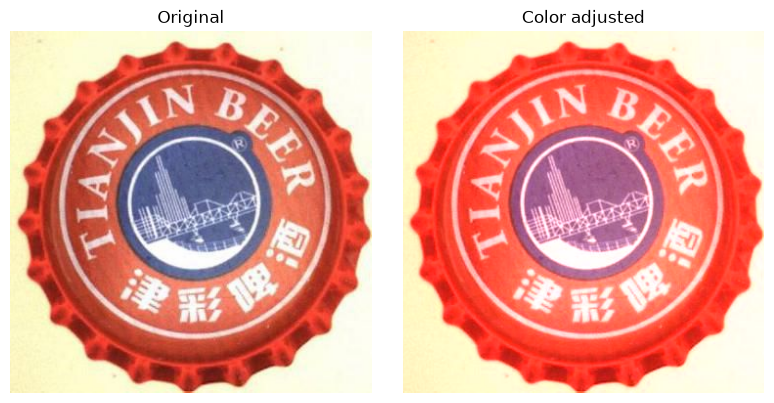

In [454]:
show_images({"Original": hw_cap, "Color adjusted": hw_color_result}, cols=2,
            save_to="作业图片/02_color.png")

运行下面这一步，准备需要的数据并检查结果。

In [455]:
print("已保存：outputs/作业图片/02_color.png")

已保存：outputs/作业图片/02_color.png


**任务三：选择一种滤波。** 默认用中值滤波处理带椒盐噪声的瓶盖图。可以保持默认，也可以将滤波一行替换为注释中的任意一种。只观察噪点和细节，不需要计算误差、比较多个方法或解释公式。


**读取图片。** 先定位文件，再解码为图像数组。`np.fromfile` 配合 `cv2.imdecode` 可以兼容中文路径；彩色图按 BGR 顺序读取。

In [456]:
image_path = ASSETS / 'bottle_cap.png'
image_bytes = np.fromfile(str(image_path), dtype=np.uint8)
hw_clean = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
if hw_clean is None:
    raise ValueError("图片读取失败，请检查文件和路径。")

运行下面这一步，准备需要的数据并检查结果。

随机数用于模拟噪声。固定种子 2026 后，重新运行能得到同样的噪声，方便比较。它不是图像处理算法的参数。

In [457]:
hw_rng = np.random.default_rng(2026)
hw_random = hw_rng.random(hw_clean.shape)
hw_noisy = hw_clean.copy()
hw_noisy[hw_random < 0.025] = 0
hw_noisy[hw_random > 0.975] = 255

执行滤波。先得到处理结果，再观察噪点与细节。

参数 `5` 表示对每个像素周围 5×5 区域取中间值。这一格只计算结果，下一步才显示；可以先预测黑白噪点会怎样变化。

In [458]:
hw_filtered = cv2.medianBlur(hw_noisy, 5)

**显示对比结果。** 前面已展开颜色转换与显示过程；这里复用 `show_images` 排版。它只负责显示和保存对比图，不执行图像处理。

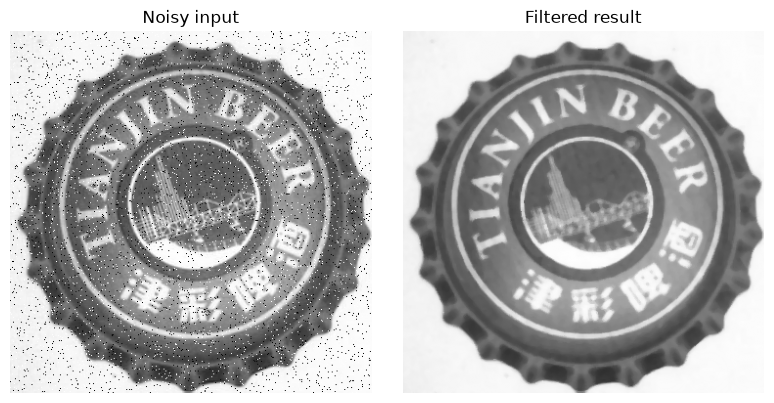

In [459]:
show_images({"Noisy input": hw_noisy, "Filtered result": hw_filtered}, cols=2,
            save_to="作业图片/03_filter.png")

运行下面这一步，准备需要的数据并检查结果。

In [460]:
print("已保存：outputs/作业图片/03_filter.png")

已保存：outputs/作业图片/03_filter.png


### 9.1 整理提交文件

将 `outputs/作业图片/` 中的三张图片复制到 `submissions/你的GitHub用户名/`，再新建一个 `README.md`。最终只需要这四个文件：

```text
submissions/
└── 你的GitHub用户名/
    ├── 01_flip.png
    ├── 02_color.png
    ├── 03_filter.png
    └── README.md
```

把下面的文字复制到自己的 `README.md`，填写三句说明：

```markdown
# 实验作业

1. 翻转：使用了____图片，水平翻转后____。
2. 颜色调整：将____通道的偏移量设为____，图像变得____。
3. 滤波：使用了____滤波，处理后____。
```

### 9.2 提交一个 PR

1. 将培训仓库 Fork 到自己的 GitHub 账号，克隆自己的 Fork，并创建作业分支，例如 `assignment/你的GitHub用户名`。如果前面已使用自己的 Fork，继续使用即可。
2. 在 VS Code 的源代码管理中，只暂存自己提交目录里的四个文件，提交并推送到自己的 Fork。运行后本 Notebook 与 `outputs/` 也可能显示已修改，这些练习文件不用加入作业 PR。
3. 从作业分支向教师仓库 `WHUT-RMers/27Tutorials` 的默认分支发起 PR，标题填写 `[作业] 你的中文姓名`，按 PR 模板勾选完成项。
4. 提交前检查文件列表：应只有 `02 机器视觉/lab/submissions/你的GitHub用户名/` 中的三张图片和一份说明。需要修改时，继续向同一分支提交，原 PR 会更新，无需新建 PR。

### 9.3 完成标准

采用“通过 / 补充后通过”：三张对比图完整、处理效果可辨认、三句说明与图片一致，即可通过。某种滤波效果不明显时，可以如实写出观察到的现象。不要求提交 Notebook、代码、长篇报告或前面各节的思考题。
